In [30]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [31]:
!pip install implicit
!pip install -q umap-learn implicit pyarrow
import os
from pathlib import Path

from implicit.als import AlternatingLeastSquares
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
import plotly.express as px
import scipy.sparse as sp

***Dataset Structure***

In [32]:
import os

BASE_DIR = "/content/drive/MyDrive/ShopSegments"
RAW_DIR = f"{BASE_DIR}/data/raw"

folders = [
    "data/raw",
    "data/processed",
    "models",
    "results",
    "plots",
    "checkpoints",

]

for folder in folders:
    os.makedirs(os.path.join(BASE_DIR, folder), exist_ok=True)


***Load Dataset***

In [33]:

import glob

csv_files = glob.glob(
    f"{RAW_DIR}/**/*.csv",
    recursive=True
)

file_paths = {
    os.path.basename(path).strip(): path
    for path in csv_files
}

required = {
    "customers": "olist_customers_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "products": "olist_products_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "location": "olist_geolocation_dataset.csv",
    "translation": "product_category_name_translation.csv"
}

data = {}

for name, filename in required.items():
    if filename not in file_paths:
        raise FileNotFoundError(filename)

    data[name] = pd.read_csv(file_paths[filename])

    print(f"{name}: {data[name].shape}")

print("\nAll datasets loaded successfully!")


customers: (99441, 5)
orders: (99441, 8)
order_items: (112650, 7)
products: (32951, 9)
payments: (103886, 5)
reviews: (99224, 7)
sellers: (3095, 4)
location: (1000163, 5)
translation: (71, 2)

All datasets loaded successfully!


***Data Quality Report***

In [34]:

quality_report = []

for name, df in data.items():

    quality_report.append({
        "Dataset": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing Values": df.isnull().sum().sum(),
        "Duplicate Rows": df.duplicated().sum()
    })

quality_df = pd.DataFrame(quality_report)

display(quality_df)

quality_df.to_csv(
    f"{BASE_DIR}/results/data_quality_report.csv",
    index=False
)

print("Data quality report saved to Google Drive!")

,Dataset,Rows,Columns,Missing Values,Duplicate Rows
0,customers,99441,5,0,0
1,orders,99441,8,4908,0
2,order_items,112650,7,0,0
3,products,32951,9,2448,0
4,payments,103886,5,0,0
5,reviews,99224,7,145903,0
6,sellers,3095,4,0,0
7,location,1000163,5,0,261831
8,translation,71,2,0,0


Data quality report saved to Google Drive!


***Cleaning***

In [35]:

customers = data["customers"].copy()
orders = data["orders"].copy()
items = data["order_items"].copy()
products = data["products"].copy()
translation = data["translation"].copy()

orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    errors="coerce"
)

delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

delivered_orders = delivered_orders.dropna(
    subset=["order_purchase_timestamp"]
)

print("Delivered orders:", len(delivered_orders))

items = items.drop_duplicates(
    subset=["order_id", "order_item_id"]
)

transactions = delivered_orders.merge(
    customers[
        ["customer_id", "customer_unique_id",
         "customer_city", "customer_state"]
    ],
    on="customer_id",
    how="inner",
    validate="many_to_one"
)

transactions = transactions.merge(
    items,
    on="order_id",
    how="inner",
    validate="one_to_many"
)

transactions = transactions.merge(
    products[
        ["product_id", "product_category_name"]
    ],
    on="product_id",
    how="left",
    validate="many_to_one"
)

transactions = transactions.merge(
    translation,
    on="product_category_name",
    how="left",
    validate="many_to_one"
)

transactions = transactions.dropna(
    subset=[
        "customer_unique_id",
        "order_id",
        "product_id",
        "order_purchase_timestamp",
        "price",
        "freight_value"
    ]
)

transactions = transactions[
    np.isfinite(transactions["price"]) &
    np.isfinite(transactions["freight_value"])
]

transactions = transactions[
    (transactions["price"] > 0) &
    (transactions["freight_value"] >= 0)
].copy()

transactions["product_category_name_english"] = (
    transactions["product_category_name_english"]
    .fillna("unknown")
)

transactions["item_total"] = (
    transactions["price"] + transactions["freight_value"]
)

print("\nTransaction cleaning completed!")
print("Final rows:", len(transactions))
print("Unique customers:", transactions["customer_unique_id"].nunique())
print("Unique orders:", transactions["order_id"].nunique())
print("Unique products:", transactions["product_id"].nunique())

display(transactions.head())


Delivered orders: 96478

Transaction cleaning completed!
Final rows: 110197
Unique customers: 93358
Unique orders: 96478
Unique products: 32216


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_city,customer_state,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_category_name_english,item_total
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,sao paulo,SP,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,utilidades_domesticas,housewares,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,barreiras,BA,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76,perfumaria,perfumery,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,vianopolis,GO,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,automotivo,auto,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,7c142cf63193a1473d2e66489a9ae977,sao goncalo do amarante,RN,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20,pet_shop,pet_shop,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,72632f0f9dd73dfee390c9b22eb56dd6,santo andre,SP,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72,papelaria,stationery,28.62


In [36]:

PROCESSED_DIR = f"{BASE_DIR}/data/processed"

os.makedirs(PROCESSED_DIR, exist_ok=True)

transactions.to_csv(
    f"{PROCESSED_DIR}/clean_transactions.csv",
    index=False
)

transactions.to_pickle(
    f"{PROCESSED_DIR}/clean_transactions.pkl"
)

print("Clean transactions saved successfully!")


Clean transactions saved successfully!


***Cleaning Report***

In [37]:

cleaning_report = {
    "total_transactions": len(transactions),
    "unique_customers": transactions["customer_unique_id"].nunique(),
    "unique_orders": transactions["order_id"].nunique(),
    "unique_products": transactions["product_id"].nunique(),
    "missing_values": int(transactions.isnull().sum().sum()),
    "duplicate_rows": int(transactions.duplicated().sum()),
    "total_revenue": round(transactions["item_total"].sum(), 2),
    "date_start": str(transactions["order_purchase_timestamp"].min()),
    "date_end": str(transactions["order_purchase_timestamp"].max())
}

cleaning_df = pd.DataFrame(
    list(cleaning_report.items()),
    columns=["Metric", "Value"]
)

display(cleaning_df)

cleaning_df.to_csv(
    f"{BASE_DIR}/results/cleaning_report.csv",
    index=False
)

print("Cleaning report saved!")


,Metric,Value
0,total_transactions,110197
1,unique_customers,93358
2,unique_orders,96478
3,unique_products,32216
4,missing_values,1562
5,duplicate_rows,0
6,total_revenue,15419773.75
7,date_start,2016-09-15 12:16:38
8,date_end,2018-08-29 15:00:37


Cleaning report saved!


***Customer RFM Dataset***

In [52]:

from pathlib import Path
import pandas as pd

BASE_DIR = Path("/content/drive/MyDrive/ShopSegments")
PROCESSED_DIR = BASE_DIR / "data" / "processed"
RESULTS_DIR = BASE_DIR / "results"

transactions["order_purchase_timestamp"] = pd.to_datetime(
    transactions["order_purchase_timestamp"]
)

transactions["product_category_name"] = (
    transactions["product_category_name"].fillna("unknown")
)

reference_date = (
    transactions["order_purchase_timestamp"].max()
    + pd.Timedelta(days=1)
)

rfm = transactions.groupby("customer_unique_id").agg(
    recency=("order_purchase_timestamp",
             lambda x: (reference_date - x.max()).days),
    frequency=("order_id", "nunique"),
    monetary=("price", "sum"),
    total_freight=("freight_value", "sum"),
    total_spend_including_freight=("item_total", "sum"),
    last_purchase=("order_purchase_timestamp", "max"),
    first_purchase=("order_purchase_timestamp", "min"),
    unique_products=("product_id", "nunique")
).reset_index()

rfm.to_csv(PROCESSED_DIR / "customer_rfm.csv", index=False)
rfm.to_pickle(PROCESSED_DIR / "customer_rfm.pkl")

rfm_report = pd.DataFrame({
    "Metric": [
        "Total Customers",
        "Missing Values",
        "Duplicate Customers",
        "Minimum Recency",
        "Maximum Recency",
        "Average Frequency",
        "Average Monetary"
    ],
    "Value": [
        len(rfm),
        rfm.isnull().sum().sum(),
        rfm["customer_unique_id"].duplicated().sum(),
        rfm["recency"].min(),
        rfm["recency"].max(),
        round(rfm["frequency"].mean(), 2),
        round(rfm["monetary"].mean(), 2)
    ]
})

rfm_report.to_csv(RESULTS_DIR / "rfm_report.csv", index=False)

print("Customer RFM dataset created!")
print("Reference Date:", reference_date.date())
print("RFM Shape:", rfm.shape)
display(rfm.head())
display(rfm_report)


Customer RFM dataset created!
Reference Date: 2018-08-30
RFM Shape: (93358, 9)


,customer_unique_id,recency,frequency,monetary,total_freight,total_spend_including_freight,last_purchase,first_purchase,unique_products
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90,12.00,141.90,2018-05-10 10:56:27,2018-05-10 10:56:27,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90,8.29,27.19,2018-05-07 11:11:27,2018-05-07 11:11:27,1
2,0000f46a3911fa3c0805444483337064,537,1,69.00,17.22,86.22,2017-03-10 21:05:03,2017-03-10 21:05:03,1
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99,17.63,43.62,2017-10-12 20:29:41,2017-10-12 20:29:41,1
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00,16.89,196.89,2017-11-14 19:45:42,2017-11-14 19:45:42,1


,Metric,Value
0,Total Customers,93358.00
1,Missing Values,0.00
2,Duplicate Customers,0.00
3,Minimum Recency,1.00
4,Maximum Recency,714.00
5,Average Frequency,1.03
6,Average Monetary,141.62


***Customer Behavior EDA***

In [39]:
!pip install -q umap-learn implicit

CUSTOMER FREQUENCY ANALYSIS
One-time Customers: 90557
Repeat Customers: 2801
One-time Customer %: 97.0
Repeat Customer %: 3.0

Frequency Distribution:


,Customer Count
frequency,
1,90557
2,2573
3,181
4,28
5,9
6,5
7,3
9,1
15,1


,recency,frequency,monetary
count,93358.00,93358.00,93358.00
mean,237.94,1.03,141.62
std,152.59,0.21,215.69
min,1.00,1.00,0.85
25%,114.00,1.00,47.65
50%,219.00,1.00,89.73
75%,346.00,1.00,154.74
max,714.00,15.00,13440.00


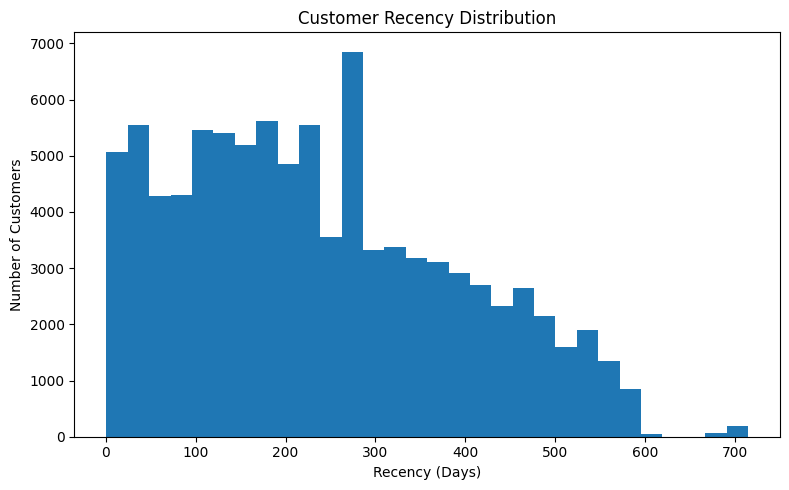

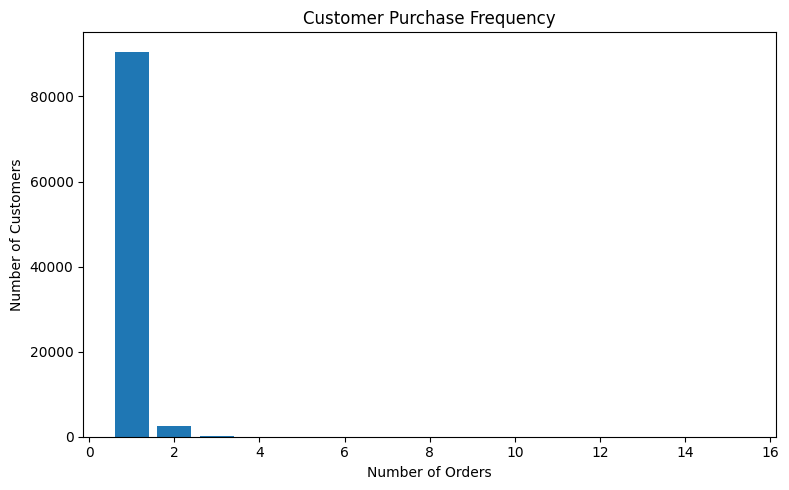

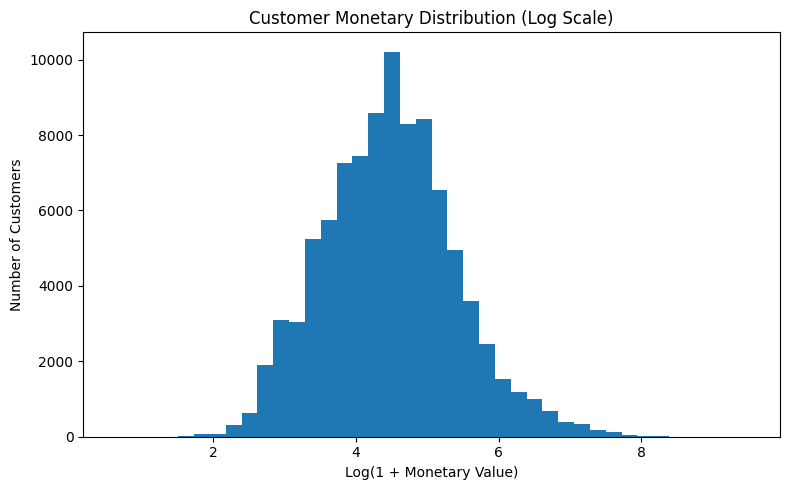

In [53]:

import numpy as np
import matplotlib.pyplot as plt

PLOTS_DIR = BASE_DIR / "plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# 1. Customer purchase frequency
frequency_counts = rfm["frequency"].value_counts().sort_index()

one_time_customers = (rfm["frequency"] == 1).sum()
repeat_customers = (rfm["frequency"] > 1).sum()

one_time_percentage = one_time_customers / len(rfm) * 100
repeat_percentage = repeat_customers / len(rfm) * 100

print("CUSTOMER FREQUENCY ANALYSIS")
print("One-time Customers:", one_time_customers)
print("Repeat Customers:", repeat_customers)
print("One-time Customer %:", round(one_time_percentage, 2))
print("Repeat Customer %:", round(repeat_percentage, 2))
print("\nFrequency Distribution:")
display(frequency_counts.head(10).to_frame("Customer Count"))

display(rfm[["recency", "frequency", "monetary"]].describe().round(2))

# 3. Recency distribution
plt.figure(figsize=(8, 5))
plt.hist(rfm["recency"], bins=30)
plt.title("Customer Recency Distribution")
plt.xlabel("Recency (Days)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "recency_distribution.png", dpi=150)
plt.show()

# 4. Frequency distribution
plt.figure(figsize=(8, 5))
plt.bar(frequency_counts.index[:10], frequency_counts.values[:10])
plt.title("Customer Purchase Frequency")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "frequency_distribution.png", dpi=150)
plt.show()

# 5. Monetary distribution (log transformed for visualization)
plt.figure(figsize=(8, 5))
plt.hist(np.log1p(rfm["monetary"]), bins=40)
plt.title("Customer Monetary Distribution (Log Scale)")
plt.xlabel("Log(1 + Monetary Value)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "monetary_distribution.png", dpi=150)
plt.show()



 ***RFM***





In [40]:
import json
from pathlib import Path
import numpy as np
import pandas as pd

BASE_DIR = Path("/content/drive/MyDrive/ShopSegments")
PROCESSED_DIR = BASE_DIR / "data" / "processed"
RESULTS_DIR = BASE_DIR / "results"
MODELS_DIR = BASE_DIR / "models"
PLOTS_DIR = BASE_DIR / "plots"
for folder in [PROCESSED_DIR, RESULTS_DIR, MODELS_DIR, PLOTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
TEST_DAYS = 60
VAL_DAYS = 60
SEGMENT_ORDER = ["Champions", "Loyal", "Potential Loyalist", "New", "At Risk", "Lost"]

FEATURES = ["recency_days", "frequency", "monetary", "avg_order_value", "unique_products"]
SILHOUETTE_SAMPLE = 10000


def clustering_matrix(df):
    from sklearn.preprocessing import StandardScaler
    raw = np.log1p(df[FEATURES].clip(lower=0).to_numpy(dtype=float))
    return StandardScaler().fit_transform(raw)


transactions = pd.read_pickle(PROCESSED_DIR / "clean_transactions.pkl")
transactions["order_purchase_timestamp"] = pd.to_datetime(transactions["order_purchase_timestamp"])
ts = transactions["order_purchase_timestamp"]

data_end = ts.max().normalize()
test_cut = data_end - pd.Timedelta(days=TEST_DAYS)
val_cut = test_cut - pd.Timedelta(days=VAL_DAYS)

train_tx = transactions[ts < test_cut].copy()
val_train_tx = transactions[ts < val_cut].copy()
val_tx = transactions[(ts >= val_cut) & (ts < test_cut)].copy()
test_tx = transactions[ts >= test_cut].copy()

train_tx.to_pickle(PROCESSED_DIR / "train_tx.pkl")
val_train_tx.to_pickle(PROCESSED_DIR / "val_train_tx.pkl")
val_tx.to_pickle(PROCESSED_DIR / "val_tx.pkl")
test_tx.to_pickle(PROCESSED_DIR / "test_tx.pkl")


def build_rfm(tx, snapshot):
    g = tx.groupby("customer_unique_id")
    out = pd.DataFrame({
        "frequency": g["order_id"].nunique(),
        "monetary": g["price"].sum(),
        "unique_products": g["product_id"].nunique(),
        "last_purchase": g["order_purchase_timestamp"].max(),
    })
    out["recency_days"] = (snapshot - out["last_purchase"]).dt.days.clip(lower=0)
    out["avg_order_value"] = out["monetary"] / out["frequency"]
    return out.drop(columns="last_purchase")


rfm = build_rfm(train_tx, test_cut)
rfm.to_pickle(PROCESSED_DIR / "rfm_train.pkl")

split_info = {
    "data_end": str(data_end.date()),
    "validation_cutoff": str(val_cut.date()),
    "test_cutoff": str(test_cut.date()),
    "train_rows": int(len(train_tx)),
    "validation_rows": int(len(val_tx)),
    "test_rows": int(len(test_tx)),
    "customers_in_segmentation": int(len(rfm)),
}
(RESULTS_DIR / "split_info.json").write_text(json.dumps(split_info, indent=2))
display(pd.Series(split_info).to_frame("value"))

,value
data_end,2018-08-29
validation_cutoff,2018-05-01
test_cutoff,2018-06-30
train_rows,95955
validation_rows,14683
test_rows,14242
customers_in_segmentation,81147


***RFM scores AND rule segments***

In [41]:
import numpy as np
import pandas as pd

rfm = pd.read_pickle(PROCESSED_DIR / "rfm_train.pkl")

rfm["R"] = 5 - pd.qcut(rfm["recency_days"].rank(method="first"), 5, labels=False).astype(int)
rfm["M"] = pd.qcut(rfm["monetary"].rank(method="first"), 5, labels=False).astype(int) + 1
rfm["F"] = np.select(
    [rfm["frequency"] >= 6, rfm["frequency"] >= 4, rfm["frequency"] == 3, rfm["frequency"] == 2],
    [5, 4, 3, 2],
    default=1,
)

rfm["segment"] = np.select(
    [
        (rfm["F"] == 1) & (rfm["R"] >= 4),
        (rfm["R"] >= 4) & (rfm["F"] >= 2) & (rfm["M"] >= 4),
        (rfm["R"] >= 3) & (rfm["F"] >= 2),
        (rfm["R"] <= 2) & (rfm["F"] >= 2),
        (rfm["R"] <= 2) & (rfm["F"] == 1),
    ],
    ["New", "Champions", "Loyal", "At Risk", "Lost"],
    default="Potential Loyalist",
)

rfm.to_pickle(PROCESSED_DIR / "rfm_scored.pkl")
display(rfm["segment"].value_counts().reindex(SEGMENT_ORDER).to_frame("customers"))

,customers
segment,
Champions,852
Loyal,719
Potential Loyalist,15748
New,31369
At Risk,850
Lost,31609


***choose Best k (elbow AND silhouette)***

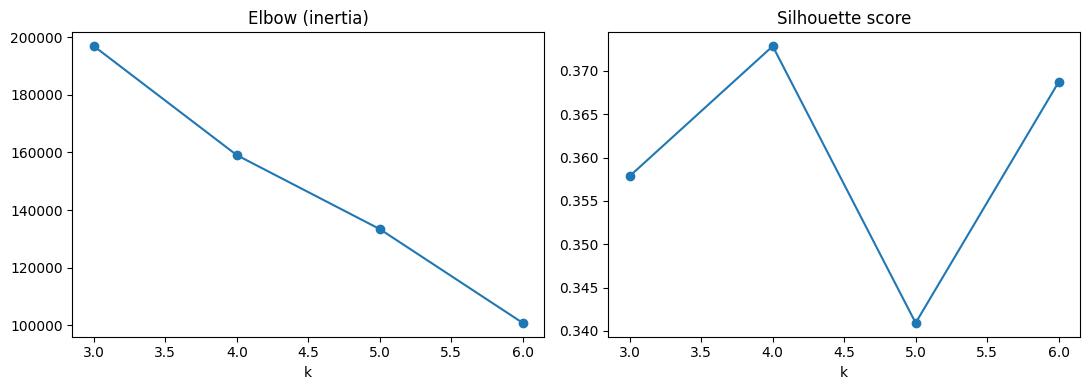

,k,inertia,silhouette,smallest_cluster_share,meets_min_size
0,3,196917.173460,0.357874,0.033224,True
1,4,159056.655574,0.372857,0.033174,True
2,5,133373.627870,0.340929,0.032879,True
3,6,100786.999840,0.368699,0.029822,False


In [42]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

K_RANGE = range(3, 7)
MIN_CLUSTER_SHARE = 0.03

rfm = pd.read_pickle(PROCESSED_DIR / "rfm_scored.pkl")
X = clustering_matrix(rfm)

rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    sizes = np.bincount(km.labels_, minlength=k) / len(X)
    rows.append({
        "k": k,
        "inertia": float(km.inertia_),
        "silhouette": float(silhouette_score(X, km.labels_, sample_size=min(SILHOUETTE_SAMPLE, len(X)), random_state=SEED)),
        "smallest_cluster_share": float(sizes.min()),
        "meets_min_size": bool(sizes.min() >= MIN_CLUSTER_SHARE),
    })
k_table = pd.DataFrame(rows)
eligible = k_table[k_table["meets_min_size"]]
pool = eligible if len(eligible) else k_table
BEST_K = int(pool.loc[pool["silhouette"].idxmax(), "k"])
k_table.to_csv(RESULTS_DIR / "k_selection.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(k_table["k"], k_table["inertia"], marker="o")
ax[0].set_title("Elbow (inertia)")
ax[0].set_xlabel("k")
ax[1].plot(k_table["k"], k_table["silhouette"], marker="o")
ax[1].set_title("Silhouette score")
ax[1].set_xlabel("k")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "k_selection.png", dpi=150)
plt.show()
display(k_table)

***K-Means, GMM, DBSCAN comparison***

In [43]:
import json
import joblib
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

DBSCAN_SAMPLE = 5000
k_table = pd.read_csv(RESULTS_DIR / "k_selection.csv")
pool = k_table[k_table["meets_min_size"]] if k_table["meets_min_size"].any() else k_table
BEST_K = int(pool.loc[pool["silhouette"].idxmax(), "k"])

rfm = pd.read_pickle(PROCESSED_DIR / "rfm_scored.pkl")
scaler = StandardScaler()
X = scaler.fit_transform(np.log1p(rfm[FEATURES].clip(lower=0).to_numpy(dtype=float)))
rule_codes = pd.factorize(rfm["segment"])[0]


def sil(labels, mask=None):
    if mask is None:
        mask = np.ones(len(labels), dtype=bool)
    sub = min(SILHOUETTE_SAMPLE, int(mask.sum()))
    return float(silhouette_score(X[mask], labels[mask], sample_size=sub, random_state=SEED))


km = KMeans(n_clusters=BEST_K, n_init=10, random_state=SEED).fit(X)
rfm["kmeans_cluster"] = km.labels_

gmm = GaussianMixture(n_components=BEST_K, covariance_type="full", random_state=SEED).fit(X)
rfm["gmm_cluster"] = gmm.predict(X)

rng = np.random.default_rng(SEED)
sample_idx = rng.choice(len(X), size=min(DBSCAN_SAMPLE, len(X)), replace=False)
dists, _ = NearestNeighbors(n_neighbors=10).fit(X[sample_idx]).kneighbors(X[sample_idx])
EPS = float(np.percentile(dists[:, -1], 90))
db = DBSCAN(eps=EPS, min_samples=10).fit(X)
rfm["dbscan_cluster"] = db.labels_
db_mask = db.labels_ != -1
db_clusters = int(len(set(db.labels_[db_mask])))

comparison = {
    "chosen_k": BEST_K,
    "kmeans_silhouette": sil(km.labels_),
    "kmeans_ari_vs_rule_segments": float(adjusted_rand_score(rule_codes, km.labels_)),
    "gmm_silhouette": sil(rfm["gmm_cluster"].to_numpy()),
    "gmm_bic": float(gmm.bic(X)),
    "gmm_ari_vs_rule_segments": float(adjusted_rand_score(rule_codes, rfm["gmm_cluster"].to_numpy())),
    "dbscan_eps": EPS,
    "dbscan_clusters": db_clusters,
    "dbscan_noise_share": float((~db_mask).mean()),
    "dbscan_silhouette_excluding_noise": sil(db.labels_, db_mask) if db_clusters >= 2 else None,
}

rfm.to_pickle(PROCESSED_DIR / "rfm_clustered.pkl")
joblib.dump({"scaler": scaler, "kmeans": km, "gmm": gmm, "features": FEATURES, "k": BEST_K},
            MODELS_DIR / "clustering_models.joblib")
(RESULTS_DIR / "clustering_comparison.json").write_text(json.dumps(comparison, indent=2))
display(pd.Series(comparison).to_frame("value"))

,value
chosen_k,4.000000e+00
kmeans_silhouette,3.728566e-01
kmeans_ari_vs_rule_segments,1.009246e-01
gmm_silhouette,2.208911e-01
gmm_bic,-2.191809e+06
gmm_ari_vs_rule_segments,7.278972e-02
dbscan_eps,3.473790e-01
dbscan_clusters,1.200000e+01
dbscan_noise_share,1.110331e-02
dbscan_silhouette_excluding_noise,4.741215e-01


***PCA AND UMAP map***

In [44]:
import umap
import plotly.express as px
from sklearn.decomposition import PCA

rfm = pd.read_pickle(PROCESSED_DIR / "rfm_clustered.pkl")
X = clustering_matrix(rfm)

pca = PCA(n_components=2, random_state=SEED).fit(X)
pca_xy = pca.transform(X)
rfm["pca_x"] = pca_xy[:, 0]
rfm["pca_y"] = pca_xy[:, 1]
pd.DataFrame({
    "component": ["PC1", "PC2"],
    "explained_variance_ratio": pca.explained_variance_ratio_,
}).to_csv(RESULTS_DIR / "pca_variance.csv", index=False)

rng = np.random.default_rng(SEED)
sample_idx = rng.choice(len(X), size=min(20000, len(X)), replace=False)
emb = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=SEED).fit_transform(X[sample_idx])

umap_df = rfm.iloc[sample_idx][["segment", "recency_days", "frequency", "monetary"]].copy()
umap_df["umap_x"] = emb[:, 0]
umap_df["umap_y"] = emb[:, 1]
umap_df.to_pickle(PROCESSED_DIR / "umap_sample.pkl")
rfm.to_pickle(PROCESSED_DIR / "rfm_clustered.pkl")

fig = px.scatter(
    umap_df, x="umap_x", y="umap_y", color="segment",
    hover_data=["recency_days", "frequency", "monetary"],
    opacity=0.6,
    title="ShopSegments customer map (UMAP)",
    category_orders={"segment": SEGMENT_ORDER},
)
fig.write_html(str(PLOTS_DIR / "segment_umap.html"), include_plotlyjs="cdn")
fig.show()

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



***Segment profiles AND marketing actions***

In [45]:
import json
import pandas as pd

SEGMENT_ACTIONS = {
    "Champions": "Early access to new collections, VIP rewards, referral invites",
    "Loyal": "Cross-sell related categories, loyalty points, bundle offers",
    "Potential Loyalist": "Second-purchase incentive, personalised picks, free-shipping threshold",
    "New": "Welcome series, review request, small discount on second order",
    "At Risk": "Win-back email with 15% off, highlight previously bought products",
    "Lost": "One low-cost reactivation email only, suppress from paid ads",
}

rfm = pd.read_pickle(PROCESSED_DIR / "rfm_clustered.pkl")
train_tx = pd.read_pickle(PROCESSED_DIR / "train_tx.pkl")
total_customers = len(rfm)
total_revenue = rfm["monetary"].sum()

cards = []
for seg in SEGMENT_ORDER:
    members = rfm[rfm["segment"] == seg]
    if members.empty:
        continue
    seg_tx = train_tx[train_tx["customer_unique_id"].isin(members.index)]
    top_products = seg_tx.groupby("product_id").size().sort_values(ascending=False).head(5).index.tolist()
    top_categories = (
        seg_tx.groupby("product_category_name_english").size()
        .sort_values(ascending=False).head(3).index.tolist()
    )
    cards.append({
        "segment": seg,
        "customers": int(len(members)),
        "customer_share": round(len(members) / total_customers, 4),
        "avg_spend": round(float(members["monetary"].mean()), 2),
        "avg_orders": round(float(members["frequency"].mean()), 2),
        "avg_recency_days": round(float(members["recency_days"].mean()), 1),
        "revenue_share": round(float(members["monetary"].sum() / total_revenue), 4),
        "top_products": top_products,
        "top_categories": top_categories,
        "suggested_action": SEGMENT_ACTIONS[seg],
    })

cards_df = pd.DataFrame(cards)
cards_df.to_csv(RESULTS_DIR / "segment_profiles.csv", index=False)
(RESULTS_DIR / "segment_cards.json").write_text(json.dumps(cards, indent=2, default=str))

kmeans_profile = (
    rfm.groupby("kmeans_cluster")[["recency_days", "frequency", "monetary", "avg_order_value"]]
    .mean().round(2)
)
kmeans_profile["customers"] = rfm.groupby("kmeans_cluster").size()
kmeans_profile.to_csv(RESULTS_DIR / "kmeans_cluster_profiles.csv")
display(cards_df[["segment", "customers", "customer_share", "avg_spend", "revenue_share", "suggested_action"]])

,segment,customers,customer_share,avg_spend,revenue_share,suggested_action
0,Champions,852,0.0105,317.63,0.0235,"Early access to new collections, VIP rewards, ..."
1,Loyal,719,0.0089,203.24,0.0127,"Cross-sell related categories, loyalty points,..."
2,Potential Loyalist,15748,0.1941,131.26,0.1797,"Second-purchase incentive, personalised picks,..."
3,New,31369,0.3866,138.88,0.3788,"Welcome series, review request, small discount..."
4,At Risk,850,0.0105,249.02,0.0184,"Win-back email with 15% off, highlight previou..."
5,Lost,31609,0.3895,140.71,0.3868,"One low-cost reactivation email only, suppress..."


***Recommender functions AND validation par model selection***

In [46]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
from implicit.als import AlternatingLeastSquares

TOP_N = 10
MIN_PRODUCT_BUYERS = 2
ITEM_NEIGHBORS = 50
ALS_ITERATIONS = 20
ALS_GRID = [
    {"factors": 32, "regularization": 1.0, "alpha": 1.0},
    {"factors": 64, "regularization": 1.0, "alpha": 1.0},
    {"factors": 64, "regularization": 10.0, "alpha": 1.0},
    {"factors": 64, "regularization": 1.0, "alpha": 5.0},
]
CHUNK = 1000
TIE_EPS = 1e-6


class Catalog:
    def __init__(self, tx):
        counts = tx.groupby(["customer_unique_id", "product_id"]).size().reset_index(name="n")
        buyers = counts.groupby("product_id")["customer_unique_id"].nunique()
        self.items = pd.Index(sorted(buyers[buyers >= MIN_PRODUCT_BUYERS].index))
        self.items_arr = self.items.to_numpy()
        self.popularity = buyers.reindex(self.items).to_numpy(dtype=float)
        counts = counts[counts["product_id"].isin(self.items)]
        self.users = pd.Index(sorted(counts["customer_unique_id"].unique()))
        r = self.users.get_indexer(counts["customer_unique_id"])
        c = self.items.get_indexer(counts["product_id"])
        self.counts = sp.csr_matrix(
            (counts["n"].to_numpy(dtype=np.float32), (r, c)),
            shape=(len(self.users), len(self.items)),
        )
        self.binary = self.counts.copy()
        self.binary.data[:] = 1.0
        self.pop_norm = self.popularity / self.popularity.max()
        self.seen_all = tx.groupby("customer_unique_id")["product_id"].apply(set).to_dict()

    @property
    def n_items(self):
        return len(self.items)


def item_similarity(binary, top_k=ITEM_NEIGHBORS):
    d = np.asarray(binary.sum(axis=0), dtype=np.float64).ravel()
    co = (binary.T @ binary).tocsr().astype(np.float64)
    co.setdiag(0)
    co.eliminate_zeros()
    co = co.tocoo()
    sim = co.data / np.sqrt(d[co.row] * d[co.col])
    S = sp.csr_matrix((sim, (co.row, co.col)), shape=co.shape).tocsr()
    rows, cols, vals = [], [], []
    for i in range(S.shape[0]):
        a, b = S.indptr[i], S.indptr[i + 1]
        if b == a:
            continue
        idx, v = S.indices[a:b], S.data[a:b]
        if len(v) > top_k:
            keep = np.argpartition(-v, top_k)[:top_k]
            idx, v = idx[keep], v[keep]
        rows.append(np.full(len(idx), i))
        cols.append(idx)
        vals.append(v)
    if not rows:
        return sp.csr_matrix(S.shape)
    return sp.csr_matrix(
        (np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))),
        shape=S.shape,
    )


def top_indices(scores, n):
    idx = np.argpartition(-scores, n - 1, axis=1)[:, :n]
    vals = np.take_along_axis(scores, idx, axis=1)
    order = np.argsort(-vals, axis=1)
    return np.take_along_axis(idx, order, axis=1)


def dense_rank(cat, rows, score_fn, n):
    out = np.empty((len(rows), n), dtype=np.int64)
    for s in range(0, len(rows), CHUNK):
        r = rows[s:s + CHUNK]
        sc = score_fn(r) + TIE_EPS * cat.pop_norm[None, :]
        seen = cat.binary[r]
        sc[seen.nonzero()] = -np.inf
        out[s:s + len(r)] = top_indices(sc, n)
    return out


def fit_als(cat, factors, regularization, alpha):
    model = AlternatingLeastSquares(
        factors=factors,
        regularization=regularization,
        alpha=alpha,
        iterations=ALS_ITERATIONS,
        random_state=SEED,
        use_gpu=False,
    )
    conf = cat.counts.copy()
    conf.data = np.log1p(conf.data)
    model.fit(conf, show_progress=False)
    return model


def als_recs(cat, model, rows, n):
    out = np.empty((len(rows), n), dtype=np.int64)
    for s in range(0, len(rows), CHUNK):
        r = rows[s:s + CHUNK]
        local = np.arange(len(r))
        ids, _ = model.recommend(local, cat.counts[r], N=n, filter_already_liked_items=True)
        ids = np.asarray(ids)
        ids[ids < 0] = 0
        out[s:s + len(r)] = ids
    return out


def generate(method, cat, customers, n, cf_matrix=None, als_model=None):
    customers = list(customers)
    warm_customers = [c for c in customers if c in cat.users]
    rows = cat.users.get_indexer(warm_customers)
    if method == "popularity":
        warm = dense_rank(cat, rows, lambda r: np.zeros((len(r), cat.n_items)), n) if len(rows) else np.empty((0, n), dtype=np.int64)
    elif method == "item_cf":
        warm = dense_rank(cat, rows, lambda r: (cat.binary[r] @ cf_matrix).toarray(), n) if len(rows) else np.empty((0, n), dtype=np.int64)
    elif method == "als":
        warm = als_recs(cat, als_model, rows, n) if len(rows) else np.empty((0, n), dtype=np.int64)
    else:
        raise ValueError(method)
    result = {c: rec for c, rec in zip(warm_customers, warm)}
    pop_rank = np.argsort(-cat.pop_norm, kind="stable")
    for c in customers:
        if c in result:
            continue
        seen = cat.seen_all.get(c, set())
        picks = []
        for i in pop_rank:
            if cat.items_arr[i] not in seen:
                picks.append(i)
                if len(picks) == n:
                    break
        result[c] = np.array(picks, dtype=np.int64)
    return result


def relevant_items(future_tx, cat, eval_customers):
    eval_set = set(eval_customers)
    fut = future_tx[future_tx["customer_unique_id"].isin(eval_set)]
    item_set = set(cat.items_arr.tolist())
    rel = {}
    for c, grp in fut.groupby("customer_unique_id")["product_id"]:
        pids = (set(grp) - cat.seen_all.get(c, set())) & item_set
        if pids:
            rel[c] = set(cat.items.get_indexer(list(pids)).tolist())
    return rel


def score_recs(recs, rel, n, n_catalog):
    precs, recalls, hits, used = [], [], [], set()
    for c, relset in rel.items():
        rec = recs[c][:n].tolist()
        used.update(rec)
        hit = len(set(rec) & relset)
        precs.append(hit / n)
        recalls.append(hit / len(relset))
        hits.append(1.0 if hit > 0 else 0.0)
    return {
        "users_evaluated": len(rel),
        f"precision_at_{n}": round(float(np.mean(precs)), 5) if precs else None,
        f"recall_at_{n}": round(float(np.mean(recalls)), 5) if recalls else None,
        "hit_rate": round(float(np.mean(hits)), 5) if hits else None,
        "coverage": round(len(used) / n_catalog, 5),
    }


val_train_tx = pd.read_pickle(PROCESSED_DIR / "val_train_tx.pkl")
val_tx = pd.read_pickle(PROCESSED_DIR / "val_tx.pkl")
cat_val = Catalog(val_train_tx)
rel_val = relevant_items(val_tx, cat_val, val_tx["customer_unique_id"].unique())
val_users = list(rel_val.keys())
cf_val = item_similarity(cat_val.binary)

validation = {}
validation["popularity"] = score_recs(generate("popularity", cat_val, val_users, TOP_N), rel_val, TOP_N, cat_val.n_items)
validation["item_cf"] = score_recs(generate("item_cf", cat_val, val_users, TOP_N, cf_matrix=cf_val), rel_val, TOP_N, cat_val.n_items)

als_grid = []
for g in ALS_GRID:
    model = fit_als(cat_val, g["factors"], g["regularization"], g["alpha"])
    recs = generate("als", cat_val, val_users, TOP_N, als_model=model)
    als_grid.append({**g, **score_recs(recs, rel_val, TOP_N, cat_val.n_items)})
BEST_ALS = max(als_grid, key=lambda r: r[f"precision_at_{TOP_N}"] or 0)
validation["als"] = {k: BEST_ALS[k] for k in ["users_evaluated", f"precision_at_{TOP_N}", f"recall_at_{TOP_N}", "hit_rate", "coverage"]}

METHODS = ["popularity", "item_cf", "als"]
CHOSEN = max(METHODS, key=lambda m: (validation[m][f"precision_at_{TOP_N}"] or 0, -METHODS.index(m)))

pd.DataFrame(als_grid).to_csv(RESULTS_DIR / "als_validation_grid.csv", index=False)
display(pd.DataFrame(validation).T)

,users_evaluated,precision_at_10,recall_at_10,hit_rate,coverage
popularity,6671.0,0.00487,0.04714,0.04767,0.00132
item_cf,6671.0,0.00493,0.04759,0.04812,0.01906
als,6671.0,0.00483,0.04677,0.04722,0.01379


In [54]:
import json
import scipy.sparse as sp

train_tx = pd.read_pickle(PROCESSED_DIR / "train_tx.pkl")
test_tx = pd.read_pickle(PROCESSED_DIR / "test_tx.pkl")
rfm = pd.read_pickle(PROCESSED_DIR / "rfm_clustered.pkl")

cat_train = Catalog(train_tx)
rel_test = relevant_items(test_tx, cat_train, test_tx["customer_unique_id"].unique())
test_users = list(rel_test.keys())
cf_train = item_similarity(cat_train.binary)
als_final = fit_als(cat_train, BEST_ALS["factors"], BEST_ALS["regularization"], BEST_ALS["alpha"])

test_all, test_warm = {}, {}
warm_rel = {u: v for u, v in rel_test.items() if u in cat_train.users}
for name in METHODS:
    cf = cf_train if name == "item_cf" else None
    al = als_final if name == "als" else None
    recs = generate(name, cat_train, test_users, TOP_N, cf_matrix=cf, als_model=al)
    test_all[name] = score_recs(recs, rel_test, TOP_N, cat_train.n_items)
    test_warm[name] = score_recs(recs, warm_rel, TOP_N, cat_train.n_items) if warm_rel else None

all_customers = sorted(rfm.index)
final_cf = cf_train if CHOSEN == "item_cf" else None
final_als = als_final if CHOSEN == "als" else None
final_recs = generate(CHOSEN, cat_train, all_customers, TOP_N, cf_matrix=final_cf, als_model=final_als)
rows = []
for c in all_customers:
    source = CHOSEN if c in cat_train.users else "popularity_cold_start"
    for rank, i in enumerate(final_recs[c], start=1):
        rows.append({"customer_unique_id": c, "rank": rank, "product_id": cat_train.items_arr[i], "source": source})
pd.DataFrame(rows).to_parquet(RESULTS_DIR / "customer_recommendations.parquet", index=False)

popular_rank = np.argsort(-cat_train.pop_norm, kind="stable")[:TOP_N]
pd.DataFrame({
    "rank": range(1, TOP_N + 1),
    "product_id": cat_train.items_arr[popular_rank],
    "buyers_in_train": cat_train.popularity[popular_rank].astype(int),
}).to_csv(RESULTS_DIR / "popularity_top10.csv", index=False)

S = cf_train.tocsr()
sim_rows = []
for i in range(S.shape[0]):
    a, b = S.indptr[i], S.indptr[i + 1]
    if b == a:
        continue
    idx, v = S.indices[a:b], S.data[a:b]
    for rank, j in enumerate(np.argsort(-v, kind="stable")[:TOP_N], start=1):
        sim_rows.append({"product_id": cat_train.items_arr[i], "rank": rank,
                         "similar_product_id": cat_train.items_arr[idx[j]], "similarity": float(v[j])})
pd.DataFrame(sim_rows).to_parquet(RESULTS_DIR / "item_similar_products.parquet", index=False)

sp.save_npz(MODELS_DIR / "item_similarity.npz", cf_train)
als_final.save(str(MODELS_DIR / "als_model.npz"))
pd.Series(cat_train.items_arr, name="product_id").to_frame().to_parquet(MODELS_DIR / "catalog_items.parquet", index=False)

recommender_metrics = {
    "chosen_method": CHOSEN,
    "validation": validation,
    "validation_als_best_params": {k: BEST_ALS[k] for k in ["factors", "regularization", "alpha"]},
    "test_all_users": test_all,
    "test_warm_users_only": test_warm,
    "test_users_evaluated": len(test_users),
    "test_cold_users": int(sum(1 for u in test_users if u not in cat_train.users)),
    "catalog_items": int(cat_train.n_items),
    "controls": [
        "Features and models use only transactions before the test cutoff.",
        "Model selection uses the validation window, not the test window.",
        "Test relevance excludes products bought before the cutoff.",
        "Customers identified by customer_unique_id.",
        "Cold-start customers get popularity recommendations and are reported separately.",
    ],
}
(RESULTS_DIR / "recommender_metrics.json").write_text(json.dumps(recommender_metrics, indent=2, default=str))
display(pd.DataFrame(test_all).T)

,users_evaluated,precision_at_10,recall_at_10,hit_rate,coverage
popularity,6185.0,0.00199,0.01951,0.01989,0.00096
item_cf,6185.0,0.00200,0.01967,0.02005,0.01478
als,6185.0,0.00199,0.01967,0.01989,0.01041
